<a href="https://colab.research.google.com/github/steffanymarcellia046/ProjectETSMachineLearning/blob/main/MODEL_QRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [45]:
import pandas as pd

# Membaca dataset Coffee Shop Sales
path = '/content/Coffee Shop Sales.xlsx'
try:
    df = pd.read_excel(path, engine='openpyxl')
    print("Dataset berhasil dibaca!")
    print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
    display(df.head())
except Exception as e:
    print(f"Gagal membaca file Excel: {e}")

Dataset berhasil dibaca!
Ukuran dataset: 149116 baris, 11 kolom


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [46]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transact

Filter data

In [47]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [48]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


,y
count,181.000000
mean,396.337017
std,129.535462
min,195.000000
25%,290.000000
50%,363.000000
75%,483.000000
max,769.000000


EDA

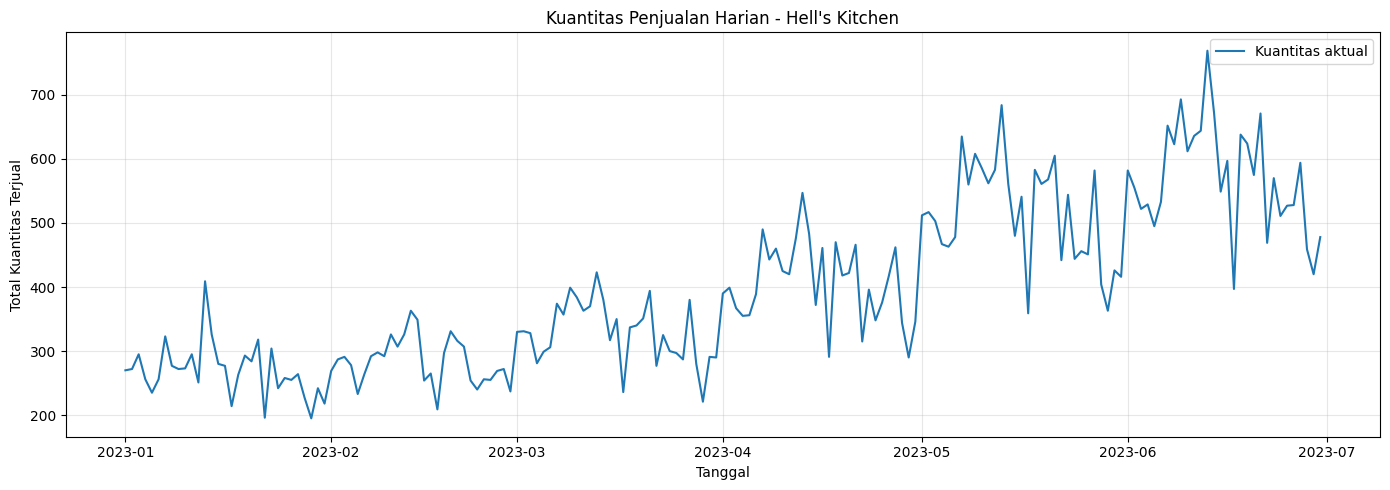

In [49]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjuala berdasarkan hari

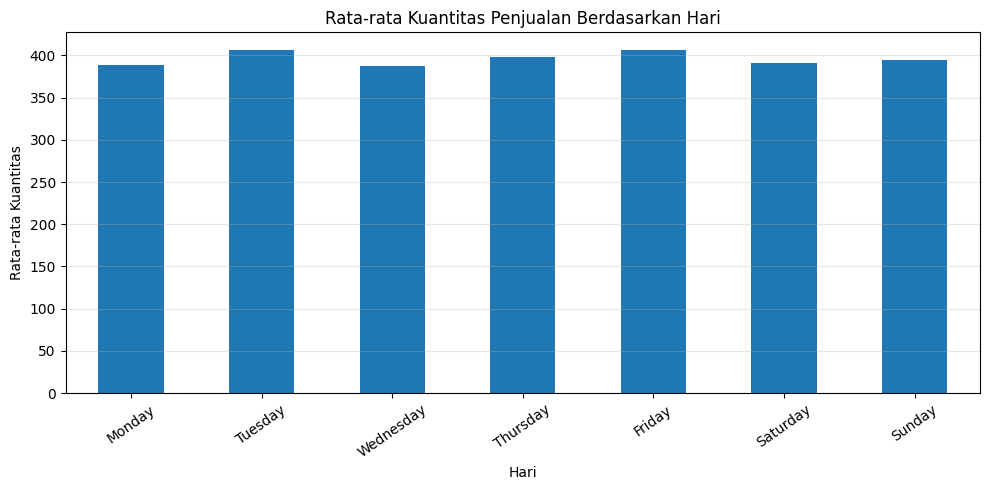

In [50]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [51]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Model Prophet

In [52]:
from prophet import Prophet

model_prophet = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_prophet.fit(train)

print("Model Prophet berhasil dilatih.")

Model Prophet berhasil dilatih.


Penjelasan konfigurasi:
- yearly_seasonality	False	Menonaktifkan pola musiman tahunan

- weekly_seasonality	True	Mengaktifkan pola musiman mingguan

- daily_seasonality	False	Menonaktifkan pola musiman harian

- seasonality_mode	"additive"	Menganggap efek musiman bersifat aditif

- interval_width	0.95	Interval prediksi 95%

- changepoint_prior_scale	Tidak diatur	Menggunakan nilai default Prophet

- seasonality_prior_scale	Tidak diatur	Menggunakan nilai default Prophet

Prediksi pada data testing

In [53]:
# Mengambil tanggal testing saja
tanggal_test = test[["ds"]].copy()

# Melakukan prediksi
pred_test = model_prophet.predict(tanggal_test)

# Menggabungkan aktual dan prediksi
hasil_test = test.merge(
    pred_test[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    how="left"
)

# Kuantitas tidak mungkin negatif.
# Nilai yhat_raw tetap disimpan untuk transparansi.
hasil_test["yhat_raw"] = hasil_test["yhat"]
hasil_test["yhat"] = hasil_test["yhat"].clip(lower=0)

display(hasil_test.head(10))

,ds,y,yhat,yhat_lower,yhat_upper,yhat_raw
0,2023-05-25,456,543.630321,425.602450,657.788491,543.630321
1,2023-05-26,451,543.404265,429.787692,663.279332,543.404265
2,2023-05-27,582,540.595157,416.870642,660.904856,540.595157
3,2023-05-28,404,548.543645,427.906301,666.110152,548.543645
4,2023-05-29,363,546.179838,428.391113,669.630661,546.179838
5,2023-05-30,426,557.560110,434.902082,685.060285,557.560110
6,2023-05-31,416,535.625965,421.529276,651.501132,535.625965
7,2023-06-01,582,564.308083,438.514010,678.223560,564.308083
8,2023-06-02,555,564.082028,457.135396,689.537678,564.082028
9,2023-06-03,522,561.272920,439.620272,683.641436,561.272920


Evaluasi model prophet

In [54]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

y_actual = hasil_test["y"].to_numpy()
y_pred = hasil_test["yhat"].to_numpy()

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

# MAPE hanya dihitung untuk nilai aktual bukan nol
mask = y_actual != 0

if mask.any():
    mape = np.mean(
        np.abs(
            (y_actual[mask] - y_pred[mask])
            / y_actual[mask]
        )
    ) * 100
else:
    mape = np.nan

# SMAPE dengan perlindungan terhadap pembagi nol
denominator = np.abs(y_actual) + np.abs(y_pred)

smape_per_baris = np.divide(
    2 * np.abs(y_actual - y_pred),
    denominator,
    out=np.zeros_like(denominator, dtype=float),
    where=denominator != 0
)

smape = np.mean(smape_per_baris) * 100

evaluasi_prophet = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "MAPE (%)", "SMAPE (%)"],
    "Nilai": [mae, rmse, mape, smape]
})

display(evaluasi_prophet.round(4))

,Metrik,Nilai
0,MAE,87.2320
1,RMSE,104.5342
2,MAPE (%),17.6828
3,SMAPE (%),15.9248


Visualisasi aktual vs prediksi

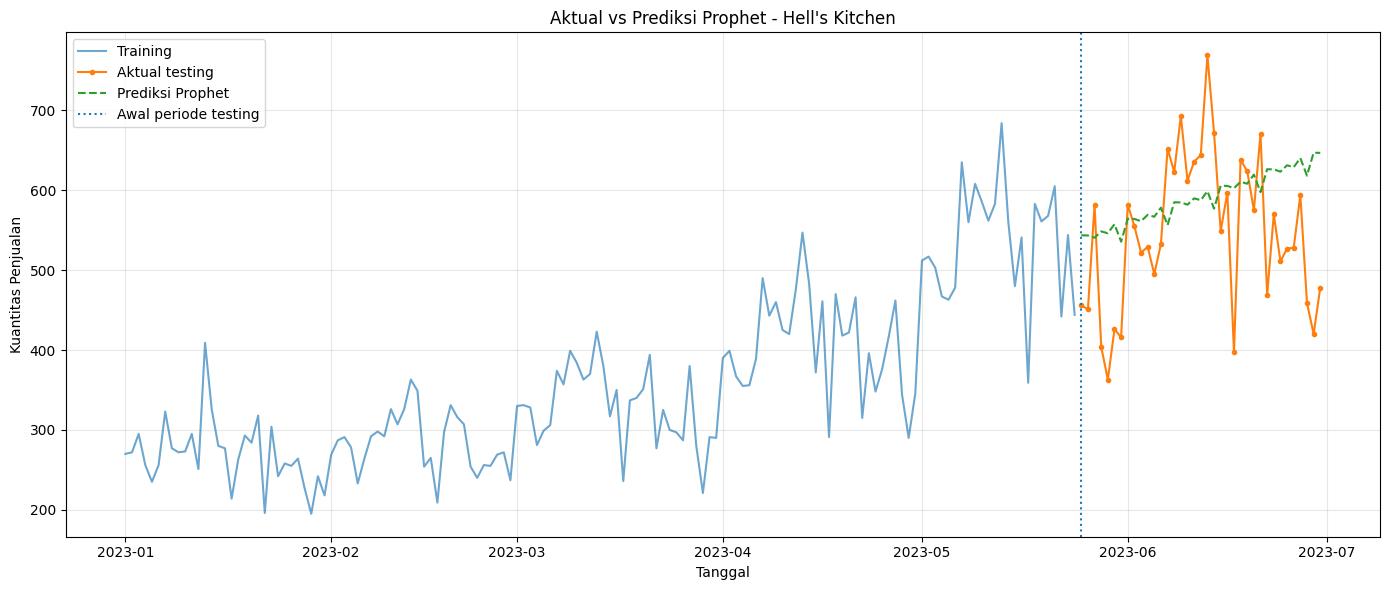

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(
    train["ds"],
    train["y"],
    label="Training",
    alpha=0.65
)

plt.plot(
    hasil_test["ds"],
    hasil_test["y"],
    label="Aktual testing",
    marker="o",
    markersize=3
)

plt.plot(
    hasil_test["ds"],
    hasil_test["yhat"],
    label="Prediksi Prophet",
    linestyle="--"
)

plt.axvline(
    test["ds"].min(),
    linestyle=":",
    label="Awal periode testing"
)

plt.title("Aktual vs Prediksi Prophet - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Prediksi 1 hari berikutnya

In [56]:
# Model final dilatih dengan seluruh data
model_final = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_final.fit(data_harian[["ds", "y"]])

# Membuat tanggal satu hari setelah data terakhir
future = model_final.make_future_dataframe(
    periods=1,
    freq="D",
    include_history=True
)

forecast = model_final.predict(future)

# Ambil tanggal setelah tanggal terakhir data aktual
tanggal_terakhir = data_harian["ds"].max()

hasil_1_hari = forecast[
    forecast["ds"] > tanggal_terakhir
][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()

# Penyesuaian untuk kuantitas yang tidak mungkin negatif
for kolom in ["yhat", "yhat_lower", "yhat_upper"]:
    hasil_1_hari[kolom] = hasil_1_hari[kolom].clip(lower=0)

# Pembulatan untuk tampilan kuantitas
hasil_1_hari["prediksi_kuantitas"] = (
    hasil_1_hari["yhat"].round().astype(int)
)

display(hasil_1_hari)

,ds,yhat,yhat_lower,yhat_upper,prediksi_kuantitas
181,2023-07-01,590.224253,457.288272,734.806591,590


Visualisasi prediksi 1 hari ke depan

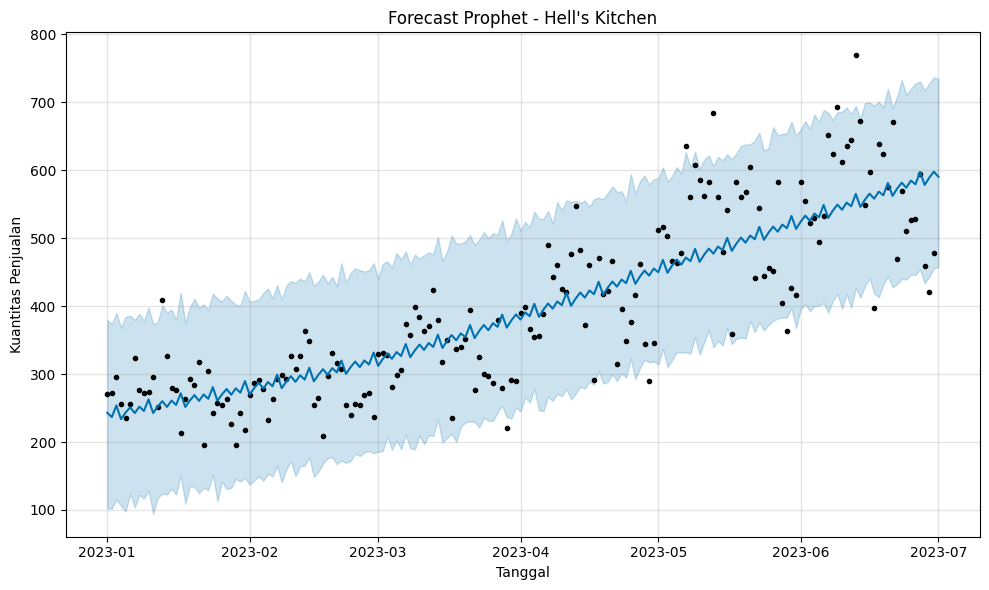

In [57]:


fig = model_final.plot(forecast)

plt.title("Forecast Prophet - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.tight_layout()
plt.show()

Cari tanggal dengan kesalahan terbesar

In [58]:
hasil_analisis = hasil_test.copy()

hasil_analisis["error"] = (
    hasil_analisis["y"] - hasil_analisis["yhat"]
)

hasil_analisis["absolute_error"] = (
    hasil_analisis["error"].abs()
)

hasil_analisis = hasil_analisis.sort_values(
    "absolute_error",
    ascending=False
)

display(
    hasil_analisis[
        ["ds", "y", "yhat", "error", "absolute_error"]
    ].head(10)
)

,ds,y,yhat,error,absolute_error
35,2023-06-29,420,647.019135,-227.019135,227.019135
23,2023-06-17,397,602.628446,-205.628446,205.628446
4,2023-05-29,363,546.179838,-183.179838,183.179838
19,2023-06-13,769,598.915636,170.084364,170.084364
36,2023-06-30,478,646.793080,-168.793080,168.793080
34,2023-06-28,459,618.337017,-159.337017,159.337017
28,2023-06-22,469,626.341372,-157.341372,157.341372
3,2023-05-28,404,548.543645,-144.543645,144.543645
5,2023-05-30,426,557.560110,-131.560110,131.560110
6,2023-05-31,416,535.625965,-119.625965,119.625965


Grafik aktual vs prediksi

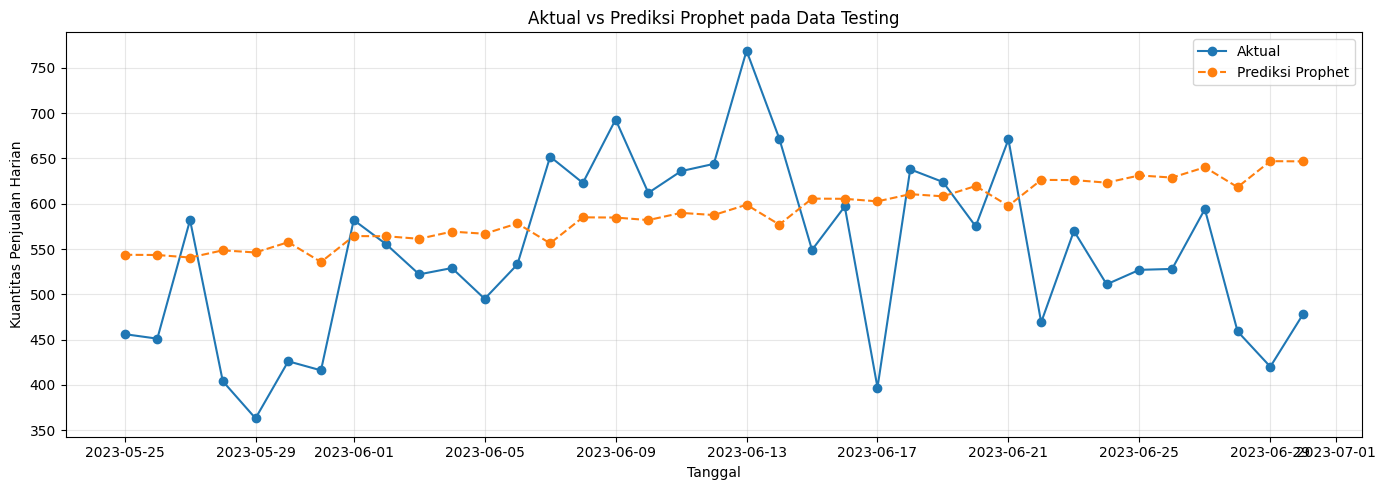

In [59]:
plt.figure(figsize=(14, 5))

plt.plot(
    hasil_test["ds"],
    hasil_test["y"],
    marker="o",
    label="Aktual"
)

plt.plot(
    hasil_test["ds"],
    hasil_test["yhat"],
    marker="o",
    linestyle="--",
    label="Prediksi Prophet"
)

plt.title("Aktual vs Prediksi Prophet pada Data Testing")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan Harian")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

COBA PERBAIKAN

Pembagian data training dan validasi

In [60]:
import pandas as pd
import numpy as np
from prophet import Prophet

# Pastikan data urut berdasarkan tanggal
data_harian = data_harian[["ds", "y"]].copy()
data_harian["ds"] = pd.to_datetime(data_harian["ds"])
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Sisihkan 20% data terakhir sebagai testing final
batas_test = int(len(data_harian) * 0.8)

data_train_val = data_harian.iloc[:batas_test].copy()
data_test_final = data_harian.iloc[batas_test:].copy()

# Bagi lagi data train_val menjadi training dan validasi
batas_val = int(len(data_train_val) * 0.8)

data_train = data_train_val.iloc[:batas_val].copy()
data_validasi = data_train_val.iloc[batas_val:].copy()

print("Jumlah data training :", len(data_train))
print("Jumlah data validasi :", len(data_validasi))
print("Jumlah data testing  :", len(data_test_final))

Jumlah data training : 115
Jumlah data validasi : 29
Jumlah data testing  : 37


Kombinasi konfigurasi

In [61]:
konfigurasi = [
    {
        "nama": "Baseline",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "CP rendah",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.01,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "CP tinggi",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.1,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "Seasonality rendah",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 1
    },
    {
        "nama": "Seasonality tinggi",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 20
    },
    {
        "nama": "Multiplicative",
        "seasonality_mode": "multiplicative",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 10
    }
]

Latih dan evaluasi konfigurasi

In [62]:
def hitung_metrik(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.asarray(prediksi, dtype=float)

    # Penjualan tidak mungkin negatif
    prediksi = np.maximum(prediksi, 0)

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE tidak dihitung pada aktual = 0
    mask = aktual != 0
    mape = (
        np.mean(np.abs(error[mask] / aktual[mask])) * 100
        if mask.any() else np.nan
    )

    # SMAPE; pasangan aktual dan prediksi yang sama-sama nol
    # diberi kontribusi error 0
    penyebut = np.abs(aktual) + np.abs(prediksi)
    smape_per_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut, dtype=float),
        where=penyebut != 0
    )
    smape = np.mean(smape_per_baris) * 100

    return mae, rmse, mape, smape


hasil_konfigurasi = []

for cfg in konfigurasi:
    model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode=cfg["seasonality_mode"],
        changepoint_prior_scale=cfg["changepoint_prior_scale"],
        seasonality_prior_scale=cfg["seasonality_prior_scale"]
    )

    model.fit(data_train)

    # Prediksi pada tanggal validasi
    future = data_validasi[["ds"]].copy()
    forecast = model.predict(future)

    aktual = data_validasi["y"].to_numpy()
    prediksi = np.maximum(forecast["yhat"].to_numpy(), 0)

    mae, rmse, mape, smape = hitung_metrik(
        aktual, prediksi
    )

    hasil_konfigurasi.append({
        "Konfigurasi": cfg["nama"],
        "Seasonality Mode": cfg["seasonality_mode"],
        "Changepoint Prior Scale": cfg["changepoint_prior_scale"],
        "Seasonality Prior Scale": cfg["seasonality_prior_scale"],
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    })

tabel_hasil = pd.DataFrame(hasil_konfigurasi)

# Urutkan berdasarkan MAE terkecil
tabel_hasil = tabel_hasil.sort_values(
    "MAE", ascending=True
).reset_index(drop=True)

display(tabel_hasil.round(4))

,Konfigurasi,Seasonality Mode,Changepoint Prior Scale,Seasonality Prior Scale,MAE,RMSE,MAPE (%),SMAPE (%)
0,CP tinggi,additive,0.10,10,90.5270,105.0658,17.6857,18.6353
1,Multiplicative,multiplicative,0.05,10,101.5128,117.1808,19.3948,21.0996
2,Baseline,additive,0.05,10,101.5896,117.2178,19.4243,21.1068
3,Seasonality rendah,additive,0.05,1,101.6235,117.2527,19.4299,21.1144
4,Seasonality tinggi,additive,0.05,20,101.7574,117.3904,19.4517,21.1448
5,CP rendah,additive,0.01,10,106.7787,122.6365,20.2927,22.2936


Menentukan konfigurasi terbaik

In [63]:
terbaik = tabel_hasil.iloc[0]

print("Konfigurasi terbaik berdasarkan MAE:")
print("Nama       :", terbaik["Konfigurasi"])
print("MAE        :", round(terbaik["MAE"], 4))
print("RMSE       :", round(terbaik["RMSE"], 4))
print("MAPE (%)   :", round(terbaik["MAPE (%)"], 4))
print("SMAPE (%)  :", round(terbaik["SMAPE (%)"], 4))

Konfigurasi terbaik berdasarkan MAE:
Nama       : CP tinggi
MAE        : 90.527
RMSE       : 105.0658
MAPE (%)   : 17.6857
SMAPE (%)  : 18.6353


QRF

In [64]:
!pip install -q quantile-forest
from quantile_forest import RandomForestQuantileRegressor

In [65]:
df_model = data_harian.copy()
df_model

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
...,...,...
176,2023-06-26,528
177,2023-06-27,594
178,2023-06-28,459
179,2023-06-29,420


Fitur Calendar

In [66]:
df_model['day_of_week'] = df_model['ds'].dt.dayofweek
df_model['day_of_month'] = df_model['ds'].dt.day
df_model['month'] = df_model['ds'].dt.month
df_model['is_weekend'] = df_model['day_of_week'].isin([5, 6]).astype(int)

In [67]:

df_model

,ds,y,day_of_week,day_of_month,month,is_weekend
0,2023-01-01,270,6,1,1,1
1,2023-01-02,272,0,2,1,0
2,2023-01-03,295,1,3,1,0
3,2023-01-04,256,2,4,1,0
4,2023-01-05,235,3,5,1,0
...,...,...,...,...,...,...
176,2023-06-26,528,0,26,6,0
177,2023-06-27,594,1,27,6,0
178,2023-06-28,459,2,28,6,0
179,2023-06-29,420,3,29,6,0


Fitur Lag 1, 7, 14 (Pola harian dan mingguan)

In [68]:
for lag in [1, 2, 3, 7, 14]:
    df_model[f'lag_{lag}'] = df_model['y'].shift(lag)

In [69]:
df_model

,ds,y,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14
0,2023-01-01,270,6,1,1,1,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,272,0,2,1,0,270.0,NaN,NaN,NaN,NaN
2,2023-01-03,295,1,3,1,0,272.0,270.0,NaN,NaN,NaN
3,2023-01-04,256,2,4,1,0,295.0,272.0,270.0,NaN,NaN
4,2023-01-05,235,3,5,1,0,256.0,295.0,272.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
176,2023-06-26,528,0,26,6,0,527.0,511.0,570.0,624.0,644.0
177,2023-06-27,594,1,27,6,0,528.0,527.0,511.0,575.0,769.0
178,2023-06-28,459,2,28,6,0,594.0,528.0,527.0,671.0,672.0
179,2023-06-29,420,3,29,6,0,459.0,594.0,528.0,469.0,549.0


Rolling Features (mean 7 hari)

In [70]:
df_model['rolling_mean_7'] = df_model['y'].shift(1).rolling(window=7).mean()
df_model['rolling_std_7'] = df_model['y'].shift(1).rolling(window=7).std()

In [71]:
df_model

,ds,y,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7,rolling_std_7
0,2023-01-01,270,6,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,272,0,2,1,0,270.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-03,295,1,3,1,0,272.0,270.0,NaN,NaN,NaN,NaN,NaN
3,2023-01-04,256,2,4,1,0,295.0,272.0,270.0,NaN,NaN,NaN,NaN
4,2023-01-05,235,3,5,1,0,256.0,295.0,272.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,2023-06-26,528,0,26,6,0,527.0,511.0,570.0,624.0,644.0,563.857143,68.809952
177,2023-06-27,594,1,27,6,0,528.0,527.0,511.0,575.0,769.0,550.142857,64.240248
178,2023-06-28,459,2,28,6,0,594.0,528.0,527.0,671.0,672.0,552.857143,65.846864
179,2023-06-29,420,3,29,6,0,459.0,594.0,528.0,469.0,549.0,522.571429,49.067495


Hapus Missing Value (Lag dan Rolling)

In [72]:
df_model = df_model.dropna().reset_index(drop=True)

In [73]:
print("Ukuran dataset setelah feature engineering:", df_model.shape)
display(df_model.head())

Ukuran dataset setelah feature engineering: (167, 13)


,ds,y,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7,rolling_std_7
0,2023-01-15,280,6,15,1,1,326.0,409.0,251.0,277.0,270.0,300.428571,53.266178
1,2023-01-16,277,0,16,1,0,280.0,326.0,409.0,272.0,272.0,300.857143,53.057920
2,2023-01-17,214,1,17,1,0,277.0,280.0,326.0,273.0,295.0,301.571429,52.636670
3,2023-01-18,263,2,18,1,0,214.0,277.0,280.0,295.0,256.0,293.142857,61.885455
4,2023-01-19,293,3,19,1,0,263.0,214.0,277.0,251.0,235.0,288.571429,62.899012


Split

In [74]:
# Tentukan fitur (X) dan target (y)
feature_cols = ['day_of_week', 'day_of_month', 'month', 'is_weekend',
                'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14',
                'rolling_mean_7', 'rolling_std_7']

X = df_model[feature_cols]
y = df_model['y']
dates = df_model['ds']

# Split Data: 80% Train, 20% Test (Kronologis)
train_size = int(len(df_model) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]
dates_train, dates_test = dates.iloc[:train_size], dates.iloc[train_size:]

print(f"Data Latih: {len(X_train)} hari | Data Uji: {len(X_test)} hari")

Data Latih: 133 hari | Data Uji: 34 hari


Tuning Optuna

In [75]:
!pip install -q optuna quantile-forest

In [88]:
import numpy as np
import pandas as pd
from quantile_forest import RandomForestQuantileRegressor
import optuna
from sklearn.metrics import mean_absolute_error

# Matikan log verbose optuna yang berlebihan
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
  # 1. Ruang pencarian hiperparameter (PERBAIKAN: hapus 'auto')
  params = {
      'n_estimators': trial.suggest_int('n_estimators', 50, 300, step=50),
      'max_depth': trial.suggest_int('max_depth', 5, 30, step=5),
      'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
      'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
      'max_features': trial.suggest_categorical(
          'max_features', ['sqrt', 'log2', 1.0, None]
      ),
  }

  # 2. Inisialisasi model
  model = RandomForestQuantileRegressor(
      **params, random_state=42, n_jobs=-1
  )

  # 3. Latih model
  model.fit(X_train, y_train)

  # 4. Prediksi pada data test (Kuantil 0.1, 0.5, 0.9 untuk interval 80%)
  preds = model.predict(X_test, quantiles=[0.05, 0.50, 0.95])
  y_pred_lower = preds[:, 0]
  y_pred_median = preds[:, 1]
  y_pred_upper = preds[:, 2]

  # 5. Evaluasi Metrik: MAE & PICP
  mae = mean_absolute_error(y_test, y_pred_median)

  in_interval = (y_test.values >= y_pred_lower) & (
      y_test.values <= y_pred_upper
  )
  picp = np.mean(in_interval)

  # 6. Fungsi Objektif Gabungan (Custom Loss)
  picp_target = 0.90
  penalty = abs(picp - picp_target) * 500
  score = mae + penalty

  return score


# 7. Jalankan Studi Optuna Kembali
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=40, show_progress_bar=True)

# 8. Tampilkan Hasil Parameter Terbaik
print('=== HASIL TUNING OPTUNA TERBAIK ===')
print(f'Score Terbaik (Loss): {study.best_value:.4f}')
print('Parameter Terbaik:')
for key, value in study.best_params.items():
  print(f'  - {key}: {value}')

  0%|          | 0/40 [00:00<?, ?it/s]

=== HASIL TUNING OPTUNA TERBAIK ===
Score Terbaik (Loss): 76.5735
Parameter Terbaik:
  - n_estimators: 50
  - max_depth: 10
  - min_samples_split: 17
  - min_samples_leaf: 1
  - max_features: sqrt


PEMODELAN

In [92]:
# 1. Masukkan parameter terbaik hasil Optuna secara otomatis menggunakan unpacking (**study.best_params)
best_params = study.best_params

print('=== PARAMETER TERBAIK YANG DIGUNAKAN ===')
for k, v in best_params.items():
  print(f'  {k}: {v}')

# 2. Inisialisasi model baru dengan parameter terbaik
optimized_qrf_model = RandomForestQuantileRegressor(
    **best_params, random_state=42, n_jobs=-1
)

# 3. Latih model pada data training
optimized_qrf_model.fit(X_train, y_train)

# 4. Prediksi Kuantil pada Data Test (0.1, 0.5, 0.9 untuk interval 80%)
preds_optimized = optimized_qrf_model.predict(X_test, quantiles=[0.05, 0.50, 0.95])
y_pred_lower_opt = preds_optimized[:, 0]  # Q10 (Bawah)
y_pred_median_opt = preds_optimized[:, 1]  # Q50 (Median)
y_pred_upper_opt = preds_optimized[:, 2]  # Q90 (Atas)

=== PARAMETER TERBAIK YANG DIGUNAKAN ===
  n_estimators: 50
  max_depth: 10
  min_samples_split: 17
  min_samples_leaf: 1
  max_features: sqrt


In [93]:
import pandas as pd

# Membuat DataFrame untuk melihat perbandingan batas bawah, median, dan batas atas hasil peramalan QRF
hasil_qrf = pd.DataFrame({
    'Tanggal': dates_test,
    'Batas Bawah (y_pred_lower)': y_pred_lower_opt,
    'Prediksi Utama (y_pred_median)': y_pred_median_opt,
    'Batas Atas (y_pred_upper)': y_pred_upper_opt
})

display(hasil_qrf)

,Tanggal,Batas Bawah (y_pred_lower),Prediksi Utama (y_pred_median),Batas Atas (y_pred_upper)
133,2023-05-28,359.00,530.5,635.00
134,2023-05-29,328.95,478.0,661.95
135,2023-05-30,344.00,464.5,596.45
136,2023-05-31,295.05,451.0,584.65
137,2023-06-01,328.05,462.0,598.10
138,2023-06-02,344.90,477.0,606.65
139,2023-06-03,386.30,560.0,661.95
140,2023-06-04,328.95,497.5,622.85
141,2023-06-05,328.95,493.0,635.00
142,2023-06-06,328.95,480.5,635.00


In [97]:
# 1. Evaluasi Point Forecast
mae_val = mean_absolute_error(y_test, y_pred_median_opt)
rmse_val = np.sqrt(mean_squared_error(y_test, y_pred_median_opt))

# 2. Evaluasi Interval (PICP & MPIW untuk interval 80% / Q10 - Q90)
# PICP: Cek berapa persen data aktual berada di antara lower dan upper
in_interval = (y_test.values >= y_pred_lower_opt) & (y_test.values <= y_pred_upper_opt)
picp = np.mean(in_interval) * 100

# MPIW: Rata-rata lebar interval
mpiw = np.mean(y_pred_upper_opt - y_pred_lower_opt)

print('=== EVALUASI LENGKAP QRF ===')
print(f'MAE  : {mae_val:.2f} transaksi')
print(f'RMSE : {rmse_val:.2f} transaksi')
print(
    f'PICP : {picp:.2f}%'
)
print(f'MPIW : {mpiw:.2f}')

=== EVALUASI LENGKAP QRF ===
MAE  : 70.69 transaksi
RMSE : 85.26 transaksi
PICP : 91.18%
MPIW : 291.04


In [96]:
import numpy as np

# 1. Pastikan y_test dan y_pred_median_opt sudah ada
# y_test: data aktual, y_pred_median_opt: prediksi Q50 dari model QRF optimal

y_true = y_test.values
y_pred = y_pred_median_opt

# 2. Hitung MAPE (Mean Absolute Percentage Error)
# Ditambah epsilon (1e-8) untuk menghindari pembagian dengan nol jika ada nilai aktual 0
mape_qrf = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

# 3. Hitung sMAPE (Symmetric Mean Absolute Percentage Error)
smape_qrf = (
    np.mean(
        2.0
        * np.abs(y_true - y_pred)
        / (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )
    * 100
)

print('=== EVALUASI PERSENTASE ERROR QRF (Q50) ===')
print(f'MAPE  : {mape_qrf:.4f}%')
print(f'sMAPE : {smape_qrf:.4f}%')

=== EVALUASI PERSENTASE ERROR QRF (Q50) ===
MAPE  : 13.0774%
sMAPE : 13.0397%


PROPHET + QRF

In [101]:
from scipy.optimize import minimize


# Fungsi objective yang ingin diminimalkan (misal: MAE)
def objective_func(weights):
  w_qrf, w_prophet = weights
  # Pastikan total bobot = 1
  ensemble_pred = (w_qrf * qrf_median) + (w_prophet * prophet_yhat)
  return mean_absolute_error(y_test, ensemble_pred)


# Batasan bobot antara 0 dan 1, dan total jumlahnya harus 1
bounds = [(0, 1), (0, 1)]
constraint = {'type': 'eq', 'fun': lambda w: 1 - sum(w)}

# Jalankan optimasi
result = minimize(
    objective_func, [0.5, 0.5], method='SLSQP', bounds=bounds, constraints=[constraint]
)
best_weights = result.x
print(f'Bobot Ideal QRF: {best_weights[0]:.4f}')
print(f'Bobot Ideal Prophet: {best_weights[1]:.4f}')

Bobot Ideal QRF: 0.9729
Bobot Ideal Prophet: 0.0271


In [100]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Ambil prediksi dari masing-masing model
# QRF Predictions (dari hasil tuning optimal Q5, Q50, Q95)
qrf_median = y_pred_median_opt
qrf_lower = y_pred_lower_opt
qrf_upper = y_pred_upper_opt

# Menyelaraskan prediksi Prophet berdasarkan tanggal yang ada di dates_test (34 baris)
prophet_aligned = hasil_test[hasil_test['ds'].isin(dates_test)].sort_values('ds')

prophet_yhat = prophet_aligned['yhat'].values
prophet_lower = prophet_aligned['yhat_lower'].values
prophet_upper = prophet_aligned['yhat_upper'].values

# 2. Tentukan Bobot Ensembel (70% QRF, 30% Prophet)
w_qrf = 0.9
w_prophet = 0.1

# 3. Hitung Ensembel Point Forecast (Median / yhat)
ensemble_median = (w_qrf * qrf_median) + (w_prophet * prophet_yhat)

# 4. Hitung Ensembel Prediction Interval (Memanfaatkan lebar interval QRF)
qrf_half_width = (qrf_upper - qrf_lower) / 2
ensemble_lower = ensemble_median - qrf_half_width
ensemble_upper = ensemble_median + qrf_half_width

# 5. Evaluasi Performa Model Ensembel
mae_ens = mean_absolute_error(y_test, ensemble_median)
rmse_ens = np.sqrt(mean_squared_error(y_test, ensemble_median))

# MAPE & sMAPE Ensembel
mape_ens = (
    np.mean(np.abs((y_test.values - ensemble_median) / (y_test.values + 1e-8)))
    * 100
)
smape_ens = (
    np.mean(
        2.0
        * np.abs(y_test.values - ensemble_median)
        / (np.abs(y_test.values) + np.abs(ensemble_median) + 1e-8)
    )
    * 100
)

# PICP & MPIW Ensembel
in_interval_ens = (y_test.values >= ensemble_lower) & (
    y_test.values <= ensemble_upper
)
picp_ens = np.mean(in_interval_ens) * 100
mpiw_ens = np.mean(ensemble_upper - ensemble_lower)

print('=== EVALUASI MODEL ENSEMBEL (QRF + PROPHET) ===')
print(f'MAE   : {mae_ens:.2f} transaksi')
print(f'RMSE  : {rmse_ens:.2f} transaksi')
print(f'MAPE  : {mape_ens:.4f}%')
print(f'sMAPE : {smape_ens:.4f}%')
print(f'PICP  : {picp_ens:.2f}% (Target ~90%)')
print(f'MPIW  : {mpiw_ens:.2f}')

=== EVALUASI MODEL ENSEMBEL (QRF + PROPHET) ===
MAE   : 70.89 transaksi
RMSE  : 84.98 transaksi
MAPE  : 13.2729%
sMAPE : 13.0885%
PICP  : 91.18% (Target ~90%)
MPIW  : 291.04
